# Geothermie-Kennlinie (Erdsonden-Lookup-Tabelle)
**nPro-Formel — Aufgabe 3**

Baut eine Kennlinie, die Spitzen-Wärmeleistung (kW) auf Anzahl der Erdsonden
und benötigte Grundstücksfläche (m²) abbildet — mit derselben Formel, die nPro
intern verwendet.

Feste Annahmen:
- Sondenlänge: 100 m
- Sondenabstand: 8 m
- Wärmeleitfähigkeit: 2,5 W/(mK) (Standard-Untergrund NRW)
- Spezifische Entzugsleistung: 50 W/m (typisch für 100-m-Sonde, NRW-Untergrund)
- Planungszeitraum: 50 Jahre

**Warum die Formel statt nPro per Hand:** nPro 30+ Mal manuell für jede
Leistungsstufe laufen zu lassen würde Stunden dauern. Die nPro-Sondendimensionierung
nutzt eine Standardformel aus EN 15450 / VDI 4640, die sich mit denselben festen
Parametern direkt in Python nachbilden lässt.

Dieses Notebook ist standalone — es liest keine Arbeitsdatei, sondern erzeugt
`nrw_results/geothermie_kennlinie.csv`, die von
`05_nrw_rasenflaeche_geothermie.ipynb` eingelesen wird.

## 1. Konfiguration

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR   = "."
OUTPUT_DIR = os.path.join(BASE_DIR, "nrw_results")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# -- Feste Annahmen ----------------------------------------------------------
PROBE_LENGTH_M     = 100    # Meter — in Deutschland per Norm fixiert
BOREHOLE_SPACING_M = 8      # Meter zwischen Sondenmitten
DESIGN_PERIOD_YR   = 50     # Jahre — nPro-Standard

# Untergrund-Parameter — Standardwerte NRW (nPro-Essen-Defaults)
THERMAL_CONDUCTIVITY = 2.5  # W/(mK) — typisches NRW-Sediment
SPEC_HEAT_EXTRACTION = 50   # W/m — spezifische Entzugsleistung je Meter Sonde
                            # (konservativer Wert fuer 100-m-Sonde, NRW-Untergrund)
                            # Quelle: VDI 4640 Blatt 1, Tabelle 4

# COP der Erdwärmepumpe (saisonaler Mittelwert)
# Fuer die Berechnung des Entzugs aus dem Untergrund:
# Q_entzug = Q_heizung x (1 - 1/COP)
HEAT_PUMP_COP = 4.0          # typischer saisonaler COP fuer NRW

# Zu durchlaufender Waermeleistungsbereich
HEAT_POWERS_KW = (list(range(5, 55, 5)) + list(range(60, 110, 10))
                  + list(range(150, 550, 50)))

print("Feste Annahmen:")
print(f'  Sondenlaenge       : {PROBE_LENGTH_M} m')
print(f'  Sondenabstand      : {BOREHOLE_SPACING_M} m')
print(f'  Waermeleitfaehigkeit: {THERMAL_CONDUCTIVITY} W/(mK)')
print(f'  Spez. Entzug       : {SPEC_HEAT_EXTRACTION} W/m')
print(f'  Waermepumpen-COP   : {HEAT_PUMP_COP}')
print(f'  Leistungsbereich   : {min(HEAT_POWERS_KW)} bis {max(HEAT_POWERS_KW)} kW')
print(f'  Stufen             : {len(HEAT_POWERS_KW)} Werte')

Feste Annahmen:
  Sondenlaenge       : 100 m
  Sondenabstand      : 8 m
  Waermeleitfaehigkeit: 2.5 W/(mK)
  Spez. Entzug       : 50 W/m
  Waermepumpen-COP   : 4.0
  Leistungsbereich   : 5 bis 500 kW
  Stufen             : 23 Werte


## 2. Sondenberechnungs-Formel

**Wie nPro Sonden berechnet:**

1. Jährlich entzogene Wärmemenge:
   `Q_entzug = Q_heizung × (1 − 1/COP)`
2. Entzugsleistung je Meter Sonde:
   `q_spez = spezifische Entzugsleistung` (W/m — aus Untergrund-Eigenschaften)
3. Benötigte Gesamtsondenlänge:
   `L_gesamt = Q_spitze × (1 − 1/COP) × 1000 / q_spez`
4. Anzahl Sonden:
   `n_sonden = ceil(L_gesamt / Sondenlaenge)`
5. Benötigte Fläche:
   Die Sonden stehen in einem Raster mit 8 m Abstand.
   Fläche = Rastergrundfläche je nach Sondenzahl.

**Quelle:** VDI 4640 Blatt 1 (Thermische Nutzung des Untergrunds), nPro-Dokumentation

In [2]:
def berechne_sonden(heat_power_kw, cop=HEAT_PUMP_COP,
                    spec_extraction=SPEC_HEAT_EXTRACTION,
                    probe_length=PROBE_LENGTH_M,
                    spacing=BOREHOLE_SPACING_M):
    """Berechnet Sondenzahl und benoetigte Flaeche fuer eine gegebene
    Spitzen-Waermeleistung.

    Parameter
    ---------
    heat_power_kw   : float — Spitzen-Heizleistung in kW
    cop             : float — saisonaler COP der Waermepumpe
    spec_extraction : float — spezifische Entzugsleistung W/m (VDI 4640)
    probe_length    : float — Sondenlaenge in Metern
    spacing         : float — Sondenabstand in Metern

    Rueckgabe
    ---------
    dict mit n_sonden, laenge_gesamt_m, flaeche_m2, raster
    """
    # Aus dem Untergrund entzogene Leistung = Heizleistung x (1 - 1/COP)
    # Bei COP=4: 75 % aus dem Untergrund, 25 % aus Strom
    entzug_kw = heat_power_kw * (1 - 1/cop)
    entzug_w  = entzug_kw * 1000

    # Benoetigte Gesamtsondenlaenge
    laenge_gesamt_m = entzug_w / spec_extraction

    # Sondenzahl (Minimum 1)
    n_sonden = max(1, int(np.ceil(laenge_gesamt_m / probe_length)))

    # Rasteranordnung — moeglichst quadratisch
    # z.B. 6 Sonden -> 2x3-Raster, 9 -> 3x3, 12 -> 3x4
    spalten = int(np.ceil(np.sqrt(n_sonden)))
    zeilen  = int(np.ceil(n_sonden / spalten))

    # Flaeche = (Spalten-1) x Abstand x (Zeilen-1) x Abstand
    # Bei Einzelsonde: Mindestflaeche = Abstand x Abstand
    if n_sonden == 1:
        flaeche_m2 = spacing ** 2
    else:
        flaeche_m2 = max(
            (spalten - 1) * spacing * (zeilen - 1) * spacing,
            spacing ** 2
        )

    return {
        "heat_power_kw":   heat_power_kw,
        "entzug_kw":       round(entzug_kw, 2),
        "laenge_gesamt_m": round(laenge_gesamt_m, 1),
        "n_sonden":        n_sonden,
        "raster":          f"{zeilen}x{spalten}",
        "flaeche_m2":      round(flaeche_m2, 1),
        "flaeche_m2_je_sonde": round(flaeche_m2 / n_sonden, 1),
    }

# Test mit 5 kW
test = berechne_sonden(5)
print("Test bei 5 kW:")
for k, v in test.items():
    print(f'  {k:<22}: {v}')

print()
test2 = berechne_sonden(100)
print("Test bei 100 kW:")
for k, v in test2.items():
    print(f'  {k:<22}: {v}')

Test bei 5 kW:
  heat_power_kw         : 5
  entzug_kw             : 3.75
  laenge_gesamt_m       : 75.0
  n_sonden              : 1
  raster                : 1x1
  flaeche_m2            : 64
  flaeche_m2_je_sonde   : 64.0

Test bei 100 kW:
  heat_power_kw         : 100
  entzug_kw             : 75.0
  laenge_gesamt_m       : 1500.0
  n_sonden              : 15
  raster                : 4x4
  flaeche_m2            : 576
  flaeche_m2_je_sonde   : 38.4


## 3. Vollständige Kennlinie aufbauen

In [3]:
zeilen_liste = [berechne_sonden(p) for p in HEAT_POWERS_KW]
kennlinie = pd.DataFrame(zeilen_liste)

print("GEOTHERMIE-KENNLINIE (ERDSONDEN)")
print("="*70)
print(f'  Sondenlaenge : {PROBE_LENGTH_M} m')
print(f'  Abstand      : {BOREHOLE_SPACING_M} m')
print(f'  COP          : {HEAT_PUMP_COP}')
print(f'  Spez. Entzug : {SPEC_HEAT_EXTRACTION} W/m  (VDI 4640, NRW-Untergrund)')
print("="*70)
print(kennlinie[["heat_power_kw", "n_sonden", "raster", "flaeche_m2"]].to_string(index=False))

# Speichern
csv_pfad = os.path.join(OUTPUT_DIR, "geothermie_kennlinie.csv")
kennlinie.to_csv(csv_pfad, index=False)
print(f'\nGespeichert: {csv_pfad}')

GEOTHERMIE-KENNLINIE (ERDSONDEN)
  Sondenlaenge : 100 m
  Abstand      : 8 m
  COP          : 4.0
  Spez. Entzug : 50 W/m  (VDI 4640, NRW-Untergrund)
 heat_power_kw  n_sonden raster  flaeche_m2
             5         1    1x1          64
            10         2    1x2          64
            15         3    2x2          64
            20         3    2x2          64
            25         4    2x2          64
            30         5    2x3         128
            35         6    2x3         128
            40         6    2x3         128
            45         7    3x3         256
            50         8    3x3         256
            60         9    3x3         256
            70        11    3x4         384
            80        12    3x4         384
            90        14    4x4         576
           100        15    4x4         576
           150        23    5x5        1024
           200        30    5x6        1280
           250        38    6x7        1920
           300

## 4. Zusammenhang visualisieren

Diagramm gespeichert


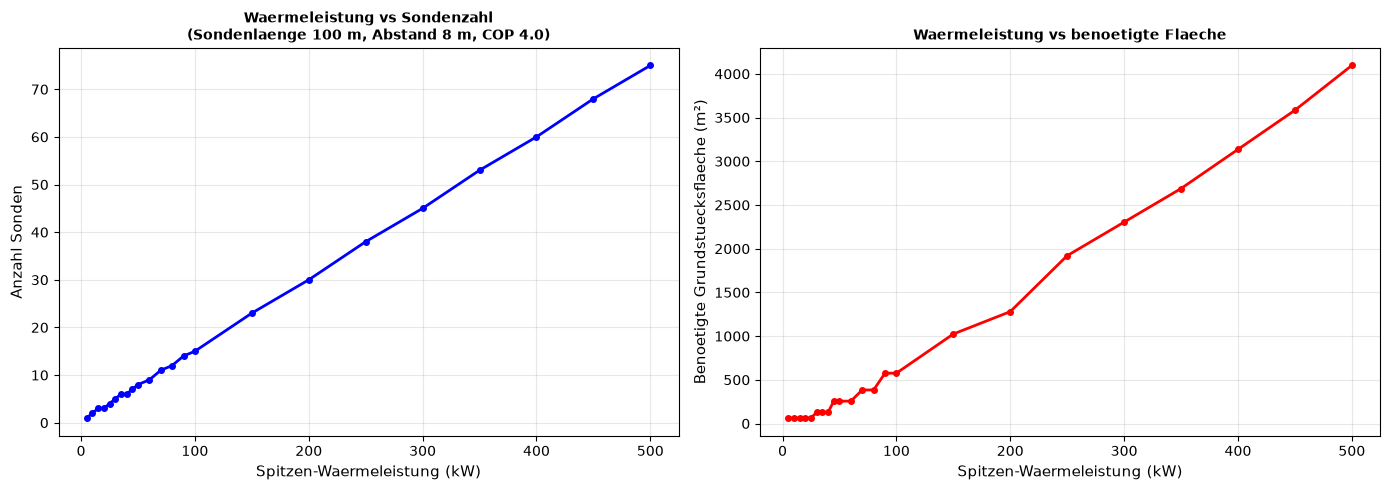

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Waermeleistung vs Sondenzahl
axes[0].plot(kennlinie["heat_power_kw"], kennlinie["n_sonden"], "b-o", lw=2, ms=4)
axes[0].set_xlabel("Spitzen-Waermeleistung (kW)", fontsize=11)
axes[0].set_ylabel("Anzahl Sonden", fontsize=11)
axes[0].set_title("Waermeleistung vs Sondenzahl\n"
                  f"(Sondenlaenge {PROBE_LENGTH_M} m, Abstand {BOREHOLE_SPACING_M} m, "
                  f"COP {HEAT_PUMP_COP})", fontsize=10, fontweight="bold")
axes[0].grid(True, alpha=0.3)

# Plot 2: Waermeleistung vs benoetigte Flaeche
axes[1].plot(kennlinie["heat_power_kw"], kennlinie["flaeche_m2"], "r-o", lw=2, ms=4)
axes[1].set_xlabel("Spitzen-Waermeleistung (kW)", fontsize=11)
axes[1].set_ylabel("Benoetigte Grundstuecksflaeche (m²)", fontsize=11)
axes[1].set_title("Waermeleistung vs benoetigte Flaeche", fontsize=10, fontweight="bold")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "geothermie_kennlinie_diagramm.pdf"), bbox_inches="tight")
print("Diagramm gespeichert")

## 5. Gegen nPro-Referenzfall validieren

Der nPro-Referenzfall zeigte:
- Wärmeentzug: 14,2 MWh jährlich, 8,2 kW Spitze
- Ergebnis: 1 × 2 = 2 Sonden

Prüfung, ob die Formel für 8,2 kW Spitzenleistung dasselbe liefert:

In [5]:
# Gegen nPro-Referenzfall validieren
npro_ergebnis = berechne_sonden(8.2)
print("Validierung gegen nPro-Referenzfall:")
print(f'  Eingangsleistung : 8.2 kW')
print(f'  nPro-Ergebnis    : 1x2 = 2 Sonden')
print(f'  Eigene Formel    : {npro_ergebnis["n_sonden"]} Sonden  '
      f'(Raster: {npro_ergebnis["raster"]})')

if npro_ergebnis["n_sonden"] == 2:
    print("  UEBEREINSTIMMUNG — Formel ist konsistent mit nPro")
else:
    print(f'  ABWEICHUNG — nPro liefert 2, Formel liefert {npro_ergebnis["n_sonden"]}')
    print("  Ggf. SPEC_HEAT_EXTRACTION-Parameter anpassen")

print(f'\n  Benoetigte Flaeche : {npro_ergebnis["flaeche_m2"]} m²')
print(f'  Gesamte Laenge     : {npro_ergebnis["laenge_gesamt_m"]} m')

Validierung gegen nPro-Referenzfall:
  Eingangsleistung : 8.2 kW
  nPro-Ergebnis    : 1x2 = 2 Sonden
  Eigene Formel    : 2 Sonden  (Raster: 1x2)
  UEBEREINSTIMMUNG — Formel ist konsistent mit nPro

  Benoetigte Flaeche : 64 m²
  Gesamte Laenge     : 123.0 m


## 6. Zusammenfassung

In [6]:
print("ZUSAMMENFASSUNG")
print("="*50)
min_zeile = kennlinie.loc[kennlinie["heat_power_kw"].idxmin()]
max_zeile = kennlinie.loc[kennlinie["heat_power_kw"].idxmax()]
print(f'  Min. Leistung : {min_zeile["heat_power_kw"]} kW -> '
      f'{min_zeile["n_sonden"]} Sonden, {min_zeile["flaeche_m2"]} m²')
print(f'  Max. Leistung : {max_zeile["heat_power_kw"]} kW -> '
      f'{max_zeile["n_sonden"]} Sonden, {max_zeile["flaeche_m2"]} m²')
print(f'\n  Gespeichert unter: nrw_results/geothermie_kennlinie.csv')
print(f'  Eintraege gesamt  : {len(kennlinie)}')

ZUSAMMENFASSUNG
  Min. Leistung : 5 kW -> 1 Sonden, 64 m²
  Max. Leistung : 500 kW -> 75 Sonden, 4096 m²

  Gespeichert unter: nrw_results/geothermie_kennlinie.csv
  Eintraege gesamt  : 23
